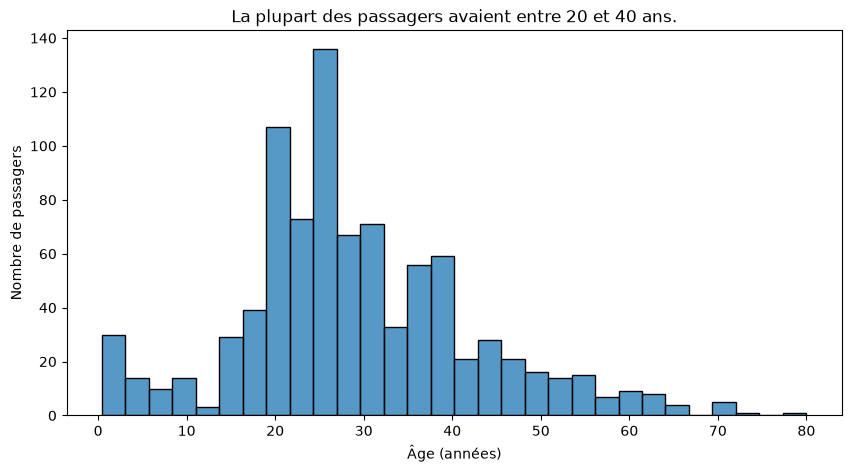

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
titanic = pd.read_csv("../exercice-08/data/titanic_propre.csv")
fig, ax = plt.subplots(figsize=(10, 5)) 
sns.histplot(data=titanic, x="age", bins=30, ax=ax)
ax.set_title("La plupart des passagers avaient entre 20 et 40 ans.")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("figures/ages.png", dpi=150, bbox_inches="tight")

### Graphique 1 : quel âge avaient les passagers ?

**Type de graphique :** histogramme, car `age` est une seule variable quantitative dont je veux voir la distribution.

**Conclusion :** la majorité des passagers avaient entre 20 et 40 ans, avec un pic vers 25 ans (environ 135 passagers dans cette tranche). Les enfants de moins de 5 ans forment un petit groupe distinct (environ 30), et les passagers de plus de 60 ans sont rares. Attention : 177 âges manquants ont été remplacés par la médiane de leur classe et de leur sexe, ce qui peut gonfler certaines barres, surtout autour de 25-30 ans.



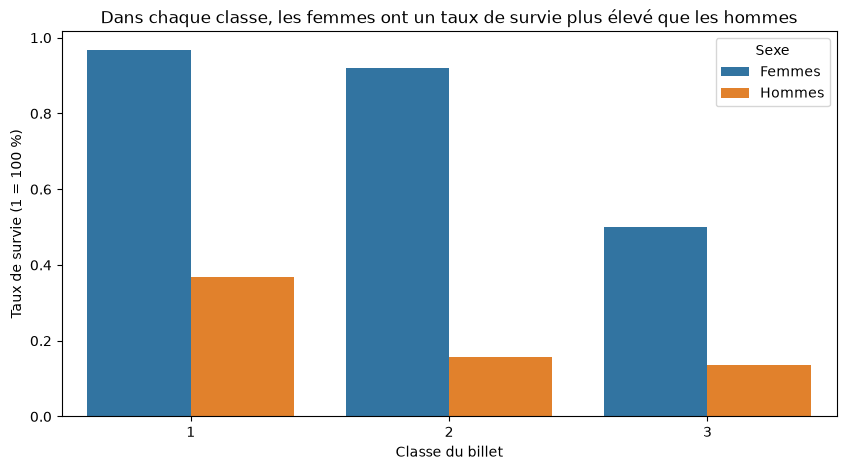

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=titanic, x="pclass", y="survived", hue="sex", errorbar=None, ax=ax)
ax.set_title("Dans chaque classe, les femmes ont un taux de survie plus élevé que les hommes")
ax.set_xlabel("Classe du billet") 
ax.set_ylabel("Taux de survie (1 = 100 %)")
ax.legend(title="Sexe", labels=["Femmes", "Hommes"]) 
fig.savefig("figures/taux_survivants_sexe.png", dpi=150, bbox_inches="tight") 

### Graphique 2 : la survie selon la classe et le sexe

**Type de graphique :** barres groupées, car je compare une mesure (le taux de survie) entre deux variables qualitatives, la classe et le sexe. La couleur sépare femmes et hommes, ce qui lui donne un sens.

**Conclusion :** dans chaque classe, les femmes ont survécu bien plus que les hommes : en 1re classe, environ 97 % des femmes contre 37 % des hommes. La classe joue aussi : le taux baisse de la 1re à la 3e classe, surtout chez les hommes (environ 14 % en 3e classe). Les femmes de 3e classe (50 %) ont même survécu davantage que les hommes de 1re classe (37 %). Ce graphique montre un lien entre sexe, classe et survie, mais pas la cause : l'âge ou d'autres facteurs peuvent aussi jouer.

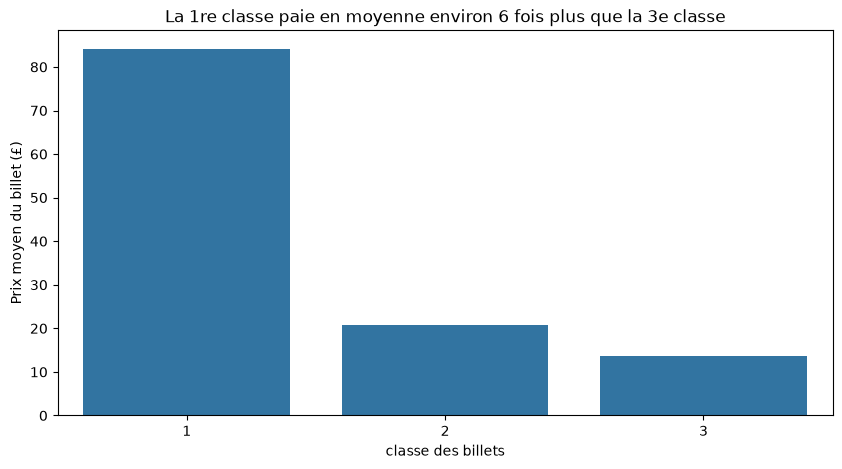

In [14]:
fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(data=titanic, x="pclass", y="fare", errorbar=None, ax=ax)
ax.set_title("La 1re classe paie en moyenne environ 6 fois plus que la 3e classe")
ax.set_xlabel("classe des billets")
ax.set_ylabel("Prix moyen du billet (£)") 
fig.savefig("figures/prix_billet_classe.png", dpi=150, bbox_inches="tight")

### Graphique 3 : le prix du billet selon la classe

**Type de graphique :** barres, car je compare une mesure (le prix moyen du billet) entre les catégories d'une variable qualitative, la classe.

**Conclusion :** le prix moyen du billet baisse nettement avec la classe : environ 84 £ en 1re classe, 21 £ en 2e et 14 £ en 3e. La 1re classe paie donc en moyenne environ 6 fois plus que la 3e. Attention : ce graphique montre une moyenne. Quelques billets de 1re classe très chers (conservés au nettoyage) tirent cette moyenne vers le haut ; un boxplot montrerait mieux la dispersion des prix à l'intérieur de chaque classe.

In [ ]:
taxis = sns.load_dataset("taxis")  
ca_jour = taxis.set_index("pickup").resample("D")["total"].sum()
print(ca_jour.head())


pickup
2019-02-28       6.30
2019-03-01    4213.83
2019-03-02    3319.02
2019-03-03    3027.32
2019-03-04    3269.08
Freq: D, Name: total, dtype: float64


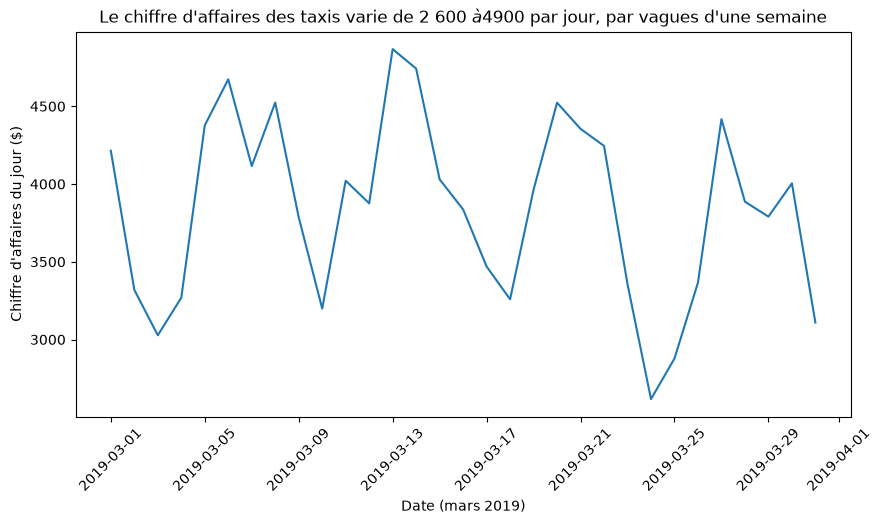

In [23]:
fig, ax = plt.subplots(figsize=(10, 5)) 
ca_jour_complet = ca_jour["2019-03-01":]
sns.lineplot(x=ca_jour_complet.index, y=ca_jour_complet.values, ax=ax)
ax.set_title("Le chiffre d'affaires des taxis varie de 2 600 $ à 4 900 $ par jour, par vagues d'une semaine")
ax.set_xlabel("Date (mars 2019)")  
ax.set_ylabel("Chiffre d'affaires du jour ($)") 
ax.tick_params(axis="x", rotation=45) 
fig.savefig("figures/ca_jour_taxis.png", dpi=150, bbox_inches="tight") 


### Graphique 4 : le chiffre d'affaires des taxis, jour après jour

**Type de graphique :** courbe, car je montre l'évolution d'une mesure (le chiffre d'affaires) au fil du temps.

**Conclusion :** en mars 2019, le chiffre d'affaires quotidien oscille entre environ 2 600 $ et 4 900 $, sans tendance nette à la hausse ou à la baisse. Il varie par vagues d'environ une semaine : les creux semblent souvent tomber sur des week-ends, mais pas à chaque fois (le samedi 30 mars est à 4 004 $). Cette hypothèse reste à vérifier par un calcul par jour de semaine. Le 28 février est retiré du graphique : une seule course y est enregistrée, la journée est incomplète et n'est pas comparable aux autres.

6433 6382


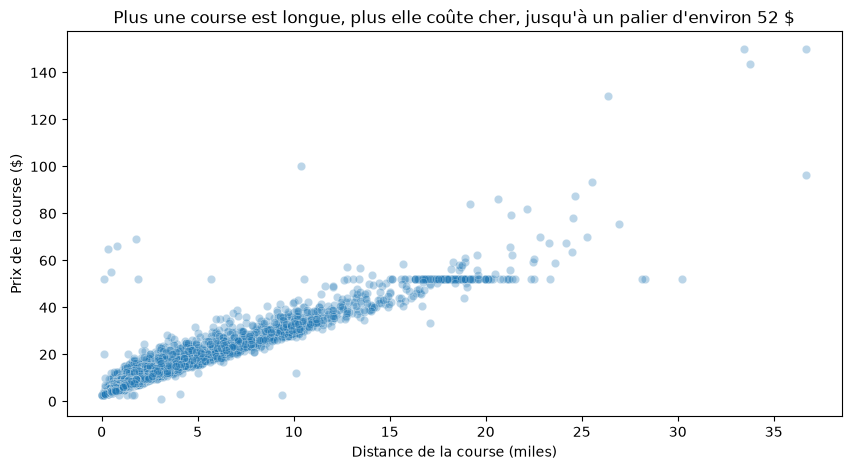

In [27]:
fig, ax = plt.subplots(figsize=(10, 5)) 
trajets_distance = taxis[taxis["distance"] > 0] 
print(len(taxis), len(trajets_distance)) 
sns.scatterplot(data=trajets_distance, x="distance", y="fare", alpha=0.3, ax=ax)
ax.set_title("Plus une course est longue, plus elle coûte cher, jusqu'à un palier d'environ 52 $") 
ax.set_xlabel("Distance de la course (miles)")  
ax.set_ylabel("Prix de la course ($)")
fig.savefig("figures/distance_prix_taxis.png", dpi=150, bbox_inches="tight")   

### Graphique 5 : le lien entre la distance et le prix des courses

**Type de graphique :** nuage de points, car je cherche le lien entre deux variables quantitatives, la distance et le prix. Chaque point est une course ; `alpha=0.3` rend les points transparents pour montrer les zones où ils sont très nombreux.

**Conclusion :** le prix augmente de façon régulière avec la distance : la grande majorité des courses font moins de 10 miles et coûtent moins de 35 $. Au-delà d'environ 17 miles, de nombreuses courses sont alignées autour de 52 $, ce qui ressemble à un tarif forfaitaire (hypothèse, non vérifiée par ces données). Quelques courses très chères pour une courte distance sortent de la tendance. X courses de distance 0 sont retirées de ce graphique : un prix y est payé sans distance enregistrée, ce qui fausse le lien étudié. Elles restent dans `taxis` pour le chiffre d'affaires.